# R4 · Query timings (Fig 2B, Supplementary Tables S3, S4)

Times the compiled searches, one thread, from query vectors / pieces computed beforehand:
* **whole tile:** the whole-matrix log scan, Spindle-naive and Spindle (g = 0.25), plus the query's own logs;
* **gene sets:** Spindle-naive (gene-set scan, its query logs timed apart), Spindle (g = 1, its pieces timed apart),
  and the padding and imputation baselines step by step.

Per seed 0–4: the first 200 held-out tiles (3 untimed warm-ups). Definitions are in `experiments/common/timing.py`.

* **Prerequisites:** `R0_index_cache`.
* **Writes:** `results/timing/`. Per dataset: `per_dataset/<key>/{whole_tile,gene_set}.csv`. Pooled: `whole_tile.csv` and
  `gene_set.csv` (one row per query, ms of every step), plus summaries `whole_tile_seeds.csv`, `whole_tile_summary.csv`,
  `gene_set_seeds.csv`, `gene_set_size_seeds.csv` and `gene_set_summary.csv`.
* **Run** it alone on an otherwise quiet machine. Timed numbers from parallel jobs on one node are not comparable. On the cluster:
  `sbatch experiments/common/timing_nb.sbatch experiments/compute/R4_timing.ipynb` (one fixed node, one timed job at a time).
  Set the thread counts to 1 (`OMP_NUM_THREADS=1` etc.) before starting Jupyter when running elsewhere.
* **Runtime / memory:** about 1–2 h; peak about 11 GB (brain_cancer: whole-matrix vectors of the index tiles).

In [1]:
import gc
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import pandas as pd

import data
import results_io as rio
import timing

FORCE = False
TOPIC = "timing"
print(data.stamp(), "| threads:", {k: os.environ.get(k) for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS")})

{'commit': 'ac3d647'} | threads: {'OMP_NUM_THREADS': '1', 'OPENBLAS_NUM_THREADS': '1'}


## Time every dataset (skipped where its files exist)

In [2]:
for key in data.indexed_keys():
    d = rio.per_dataset(TOPIC, key)
    for name, fn in (("whole_tile", timing.whole_tile), ("gene_set", timing.gene_set)):
        f = d / f"{name}.csv"
        if f.exists() and not FORCE:
            print(f"{key} {name}: exists, skipped")
            continue
        df = fn(key)
        df.to_csv(f, index=False)
        rio.register(TOPIC, f, f"{name} timings of {key}: one row per (seed, query{', size' if name == 'gene_set' else ''})", len(df))
        del df
        gc.collect()

skin_melanoma seed 0: 93 queries; median ms whole 17.58, naive 1.11, spindle 0.267; query logs whole 9.5, block 5.1
skin_melanoma seed 1: 93 queries; median ms whole 16.15, naive 1.06, spindle 0.222; query logs whole 8.6, block 4.9
skin_melanoma seed 2: 93 queries; median ms whole 15.99, naive 1.07, spindle 0.233; query logs whole 8.6, block 3.7
skin_melanoma seed 3: 93 queries; median ms whole 15.99, naive 1.07, spindle 0.240; query logs whole 8.7, block 4.9
skin_melanoma seed 4: 93 queries; median ms whole 15.87, naive 1.15, spindle 0.230; query logs whole 8.7, block 5.1
skin_melanoma seed 0: 372 queries; median ms Spindle-naive 4.71 (search 4.24, query logs 0.54), Spindle 0.097 (pieces 1.09); padding 4.2, imputation 7.9
skin_melanoma seed 1: 372 queries; median ms Spindle-naive 4.63 (search 4.12, query logs 0.53), Spindle 0.096 (pieces 1.07); padding 4.3, imputation 8.0
skin_melanoma seed 2: 372 queries; median ms Spindle-naive 4.48 (search 4.17, query logs 0.40), Spindle 0.096 (pie

## Pooled tables

In [3]:
keys = data.indexed_keys()
tw = pd.concat([pd.read_csv(rio.topic(TOPIC) / "per_dataset" / k / "whole_tile.csv") for k in keys], ignore_index=True)
tg = pd.concat([pd.read_csv(rio.topic(TOPIC) / "per_dataset" / k / "gene_set.csv") for k in keys], ignore_index=True)
rio.write_csv(tw, TOPIC, "whole_tile.csv", "whole-tile timings, one row per (dataset, seed, query): ms of every step "
              "(qlog_whole, qlog_block, whole, naive, spindle)")
rio.write_csv(tg, TOPIC, "gene_set.csv", "gene-set timings, one row per (dataset, seed, query, size): ms of every step")
w_seeds, w_sum = timing.whole_tile_tables(tw)
g_seeds, g_size, g_sum = timing.gene_set_tables(tg)
rio.write_csv(w_seeds, TOPIC, "whole_tile_seeds.csv", "whole tile: median ms of every step per (dataset, seed)")
rio.write_csv(w_sum, TOPIC, "whole_tile_summary.csv", "whole tile: mean and s.d. over seeds of the per-seed medians; "
              "speed-ups of the means")
rio.write_csv(g_seeds, TOPIC, "gene_set_seeds.csv", "gene sets: median ms per (dataset, seed), all sizes pooled")
rio.write_csv(g_size, TOPIC, "gene_set_size_seeds.csv", "gene sets: median ms per (dataset, seed, size)")
rio.write_csv(g_sum, TOPIC, "gene_set_summary.csv", "gene sets: mean and s.d. over seeds; speed-ups search only "
              "(Spindle-naive scan without query logs / Spindle) and end to end");

wrote results/timing/whole_tile.csv: 6705 rows
wrote results/timing/gene_set.csv: 26212 rows
wrote results/timing/whole_tile_seeds.csv: 40 rows
wrote results/timing/whole_tile_summary.csv: 8 rows
wrote results/timing/gene_set_seeds.csv: 40 rows
wrote results/timing/gene_set_size_seeds.csv: 160 rows
wrote results/timing/gene_set_summary.csv: 8 rows


## Whole tile: median ms (mean over seeds) and speed-ups

In [4]:
w_sum.set_index("key").loc[keys, ["qlog_whole_ms", "qlog_block_ms", "whole_ms", "naive_ms", "spindle_ms",
                                  "speedup_naive_vs_whole", "speedup_spindle_vs_naive", "speedup_spindle_vs_whole"]].round(3)

,qlog_whole_ms,qlog_block_ms,whole_ms,naive_ms,spindle_ms,speedup_naive_vs_whole,speedup_spindle_vs_naive,speedup_spindle_vs_whole
key,,,,,,,,
skin_melanoma,8.836,4.732,16.316,1.093,0.238,14.921,4.587,68.438
kidney_nondiseased,8.269,2.603,14.411,0.755,0.159,19.079,4.761,90.837
breast_cancer,5.427,3.738,24.132,1.700,0.394,14.197,4.318,61.308
lung_cancer,8.305,4.734,30.106,1.977,0.491,15.231,4.029,61.369
pancreatic_cancer,14.198,6.121,73.786,2.836,0.553,26.022,5.129,133.458
lymph_node,8.719,7.545,41.662,2.646,0.646,15.743,4.095,64.460
lymph_node_5k,11.071,22.132,114.842,7.678,2.352,14.957,3.264,48.817
brain_cancer,14.478,25.621,451.485,15.064,2.898,29.971,5.198,155.801


## Gene sets: median ms (mean over seeds) and speed-ups

In [5]:
g_sum.set_index("key").loc[keys, ["naive_partial_ms", "naive_partial_search_ms", "qlog_naive_partial_ms",
                                  "spindle_partial_ms", "qlog_spindle_partial_ms", "padding_ms", "imputation_ms",
                                  "speedup_spindle_partial", "speedup_e2e"]].round(3)

,naive_partial_ms,naive_partial_search_ms,qlog_naive_partial_ms,spindle_partial_ms,qlog_spindle_partial_ms,padding_ms,imputation_ms,speedup_spindle_partial,speedup_e2e
key,,,,,,,,,
skin_melanoma,4.569,4.089,0.521,0.098,1.030,4.108,7.726,41.914,4.053
kidney_nondiseased,3.648,3.410,0.247,0.078,0.500,2.484,4.791,43.690,6.314
breast_cancer,9.431,9.040,0.505,0.156,1.054,4.108,6.981,57.856,7.791
lung_cancer,8.007,7.568,0.524,0.147,1.041,5.128,8.598,51.438,6.741
pancreatic_cancer,6.774,6.119,0.627,0.154,1.073,7.134,11.267,39.718,5.522
lymph_node,11.640,10.940,0.902,0.208,1.701,7.728,12.452,52.614,6.098
lymph_node_5k,33.431,30.616,2.731,0.530,4.651,20.617,34.097,57.734,6.453
brain_cancer,29.106,26.047,2.747,0.443,4.923,33.131,45.212,58.738,5.423


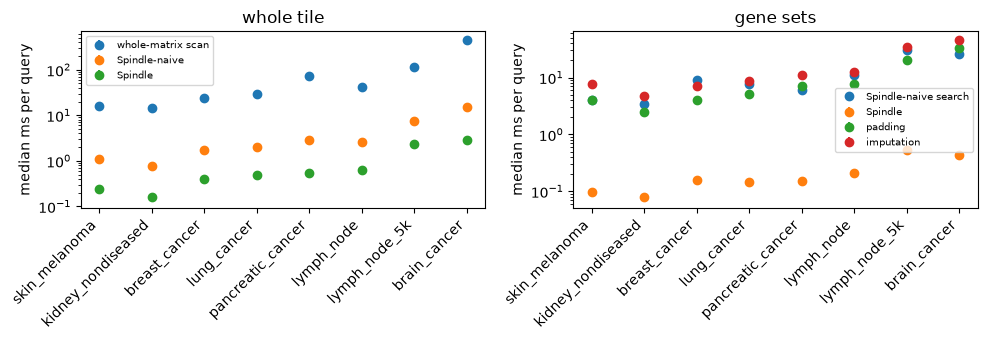

In [6]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for col, lab in (("whole_ms", "whole-matrix scan"), ("naive_ms", "Spindle-naive"), ("spindle_ms", "Spindle")):
    axs[0].errorbar(range(len(keys)), w_sum.set_index("key").loc[keys, col],
                    yerr=w_sum.set_index("key").loc[keys, col + "_sd"], fmt="o", label=lab)
for col, lab in (("naive_partial_search_ms", "Spindle-naive search"), ("spindle_partial_ms", "Spindle"),
                 ("padding_ms", "padding"), ("imputation_ms", "imputation")):
    axs[1].errorbar(range(len(keys)), g_sum.set_index("key").loc[keys, col],
                    yerr=g_sum.set_index("key").loc[keys, col + "_sd"], fmt="o", label=lab)
for ax, t in zip(axs, ("whole tile", "gene sets")):
    ax.set_yscale("log"); ax.set_xticks(range(len(keys))); ax.set_xticklabels(keys, rotation=45, ha="right")
    ax.set_ylabel("median ms per query"); ax.set_title(t); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [7]:
rio.write_manifest(TOPIC, "R4_timing.ipynb", inputs=["results/_cache (R0_index_cache)"],
                   notes="Timed one job at a time on one node (cluster: ROSALIND-CPU1), one thread.")

wrote results/timing/manifest.json: 23 files; peak memory 11.03 GB


{'topic': 'timing',
 'notebook': 'R4_timing.ipynb',
 'date': '2026-11-12 21:48',
 'commit': 'ac3d647',
 'inputs': ['results/_cache (R0_index_cache)'],
 'peak_rss_gb': 11.03,
 'notes': 'Timed one job at a time on one node (cluster: ROSALIND-CPU1), one thread.',
 'files': {'gene_set.csv': {'description': 'gene-set timings, one row per (dataset, seed, query, size): ms of every step',
   'rows': 26212,
   'bytes': 7416251},
  'gene_set_seeds.csv': {'description': 'gene sets: median ms per (dataset, seed), all sizes pooled',
   'rows': 40,
   'bytes': 12612},
  'gene_set_size_seeds.csv': {'description': 'gene sets: median ms per (dataset, seed, size)',
   'rows': 160,
   'bytes': 50004},
  'gene_set_summary.csv': {'description': 'gene sets: mean and s.d. over seeds; speed-ups search only (Spindle-naive scan without query logs / Spindle) and end to end',
   'rows': 8,
   'bytes': 5400},
  'per_dataset/brain_cancer/gene_set.csv': {'description': 'gene_set timings of brain_cancer: one row per 